В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import random

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
sequence_length = 365 * 4

In [5]:
token_num = 10

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['XMR', 'ETH', 'XRP', 'LINK', 'SOL', 'BTC', 'DOGE', 'ADA', 'DOT', 'XLM']

In [6]:
# strategy={"cooldown_long": 90, "sell_fraction": 0.5, "minimum_profit": 2.0}
strategy={}

03:07:51 - cmdstanpy - INFO - Chain [1] start processing
03:07:51 - cmdstanpy - INFO - Chain [1] done processing


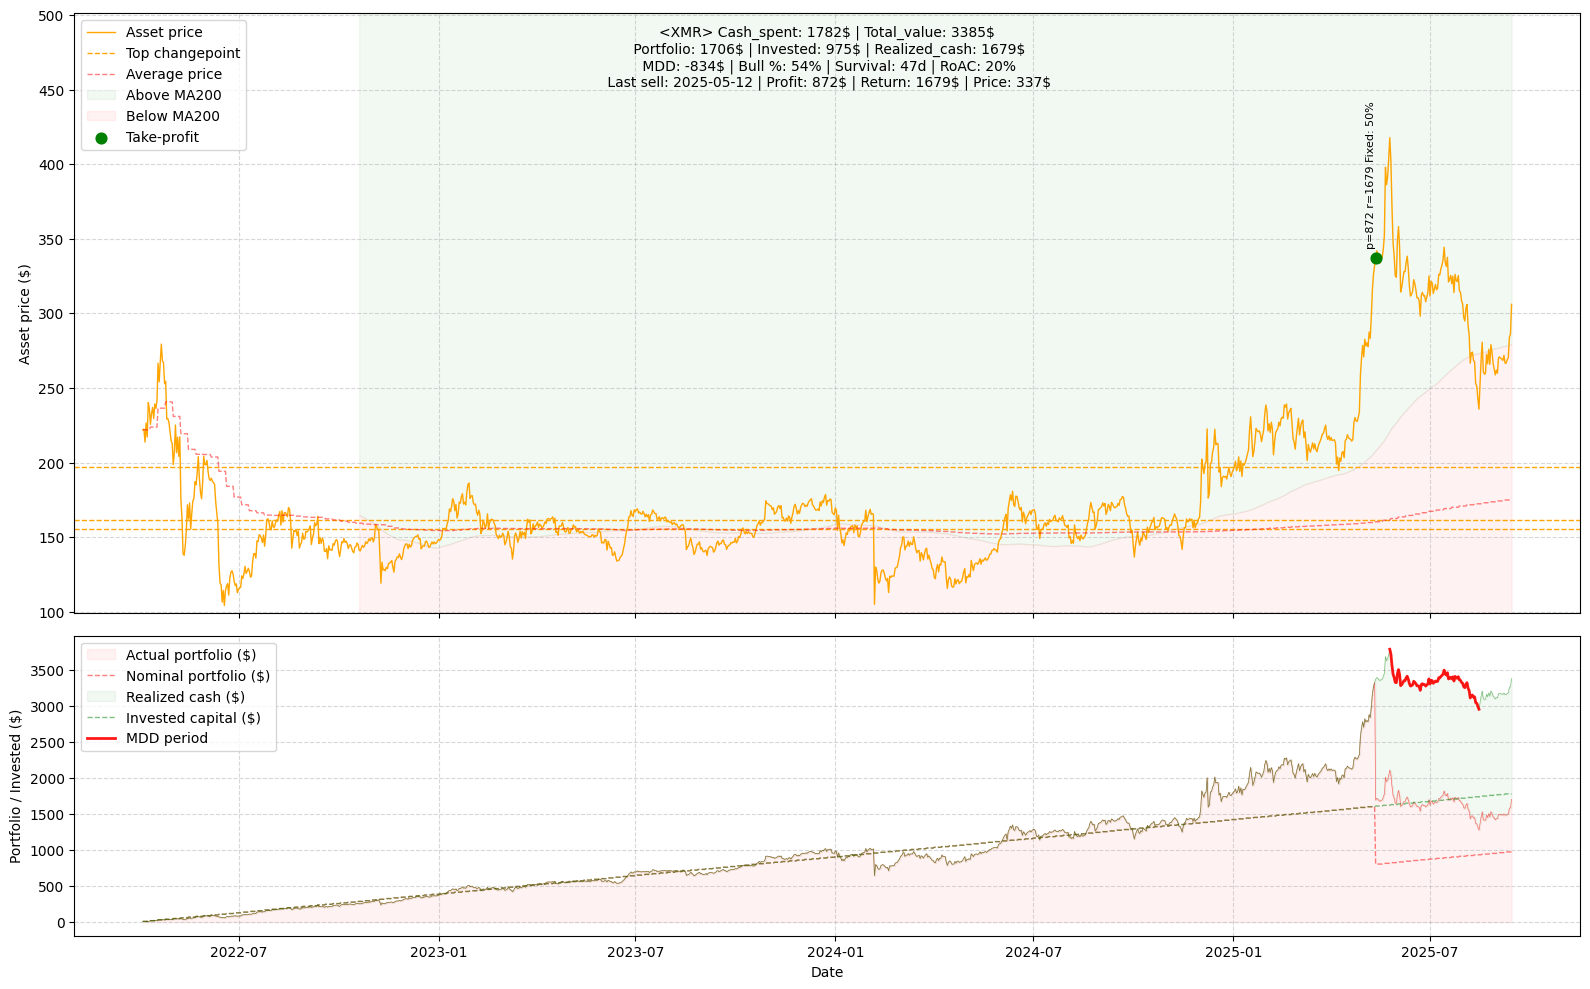

03:07:51 - cmdstanpy - INFO - Chain [1] start processing
03:07:52 - cmdstanpy - INFO - Chain [1] done processing


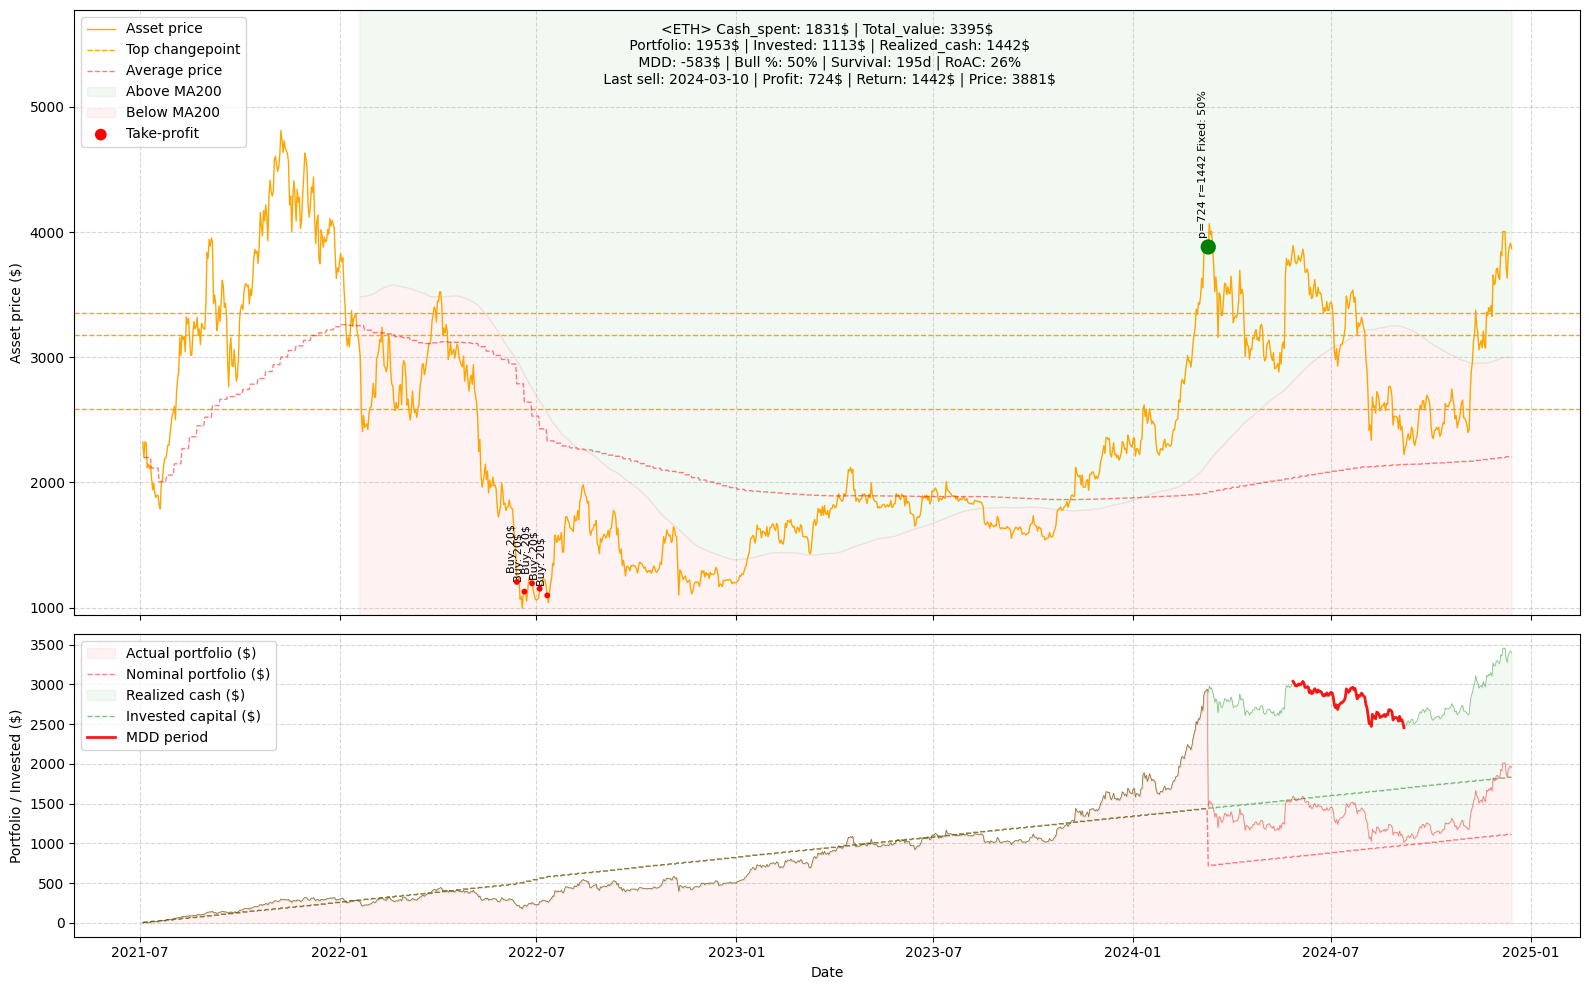

03:07:52 - cmdstanpy - INFO - Chain [1] start processing
03:07:52 - cmdstanpy - INFO - Chain [1] done processing


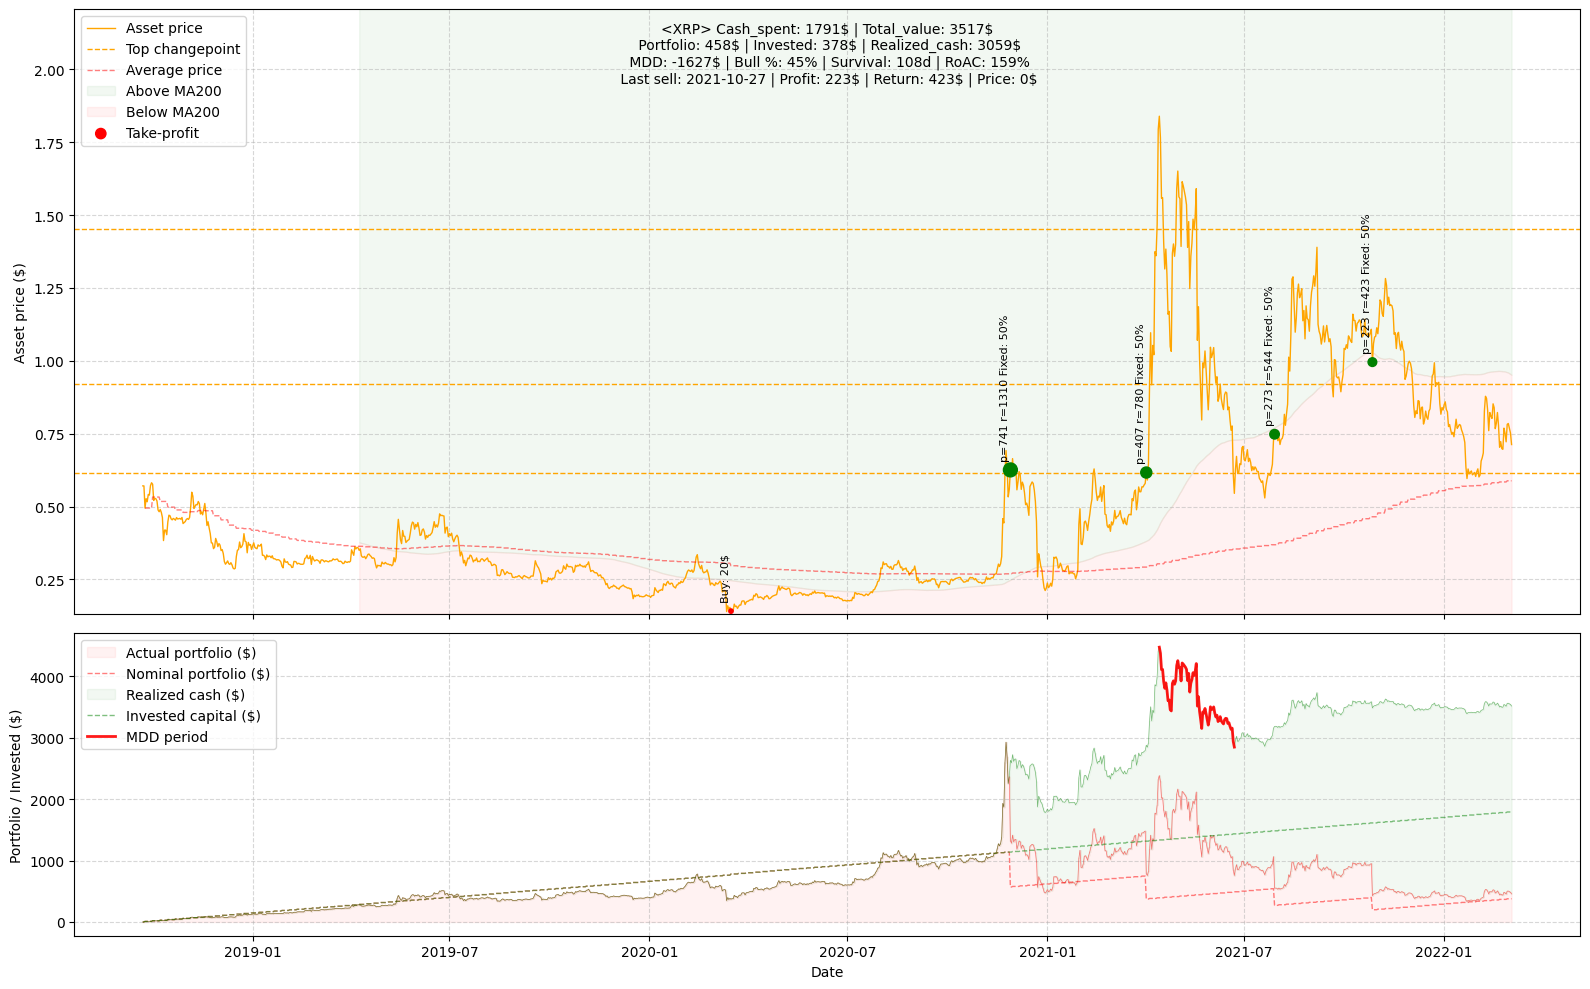

03:07:52 - cmdstanpy - INFO - Chain [1] start processing
03:07:53 - cmdstanpy - INFO - Chain [1] done processing


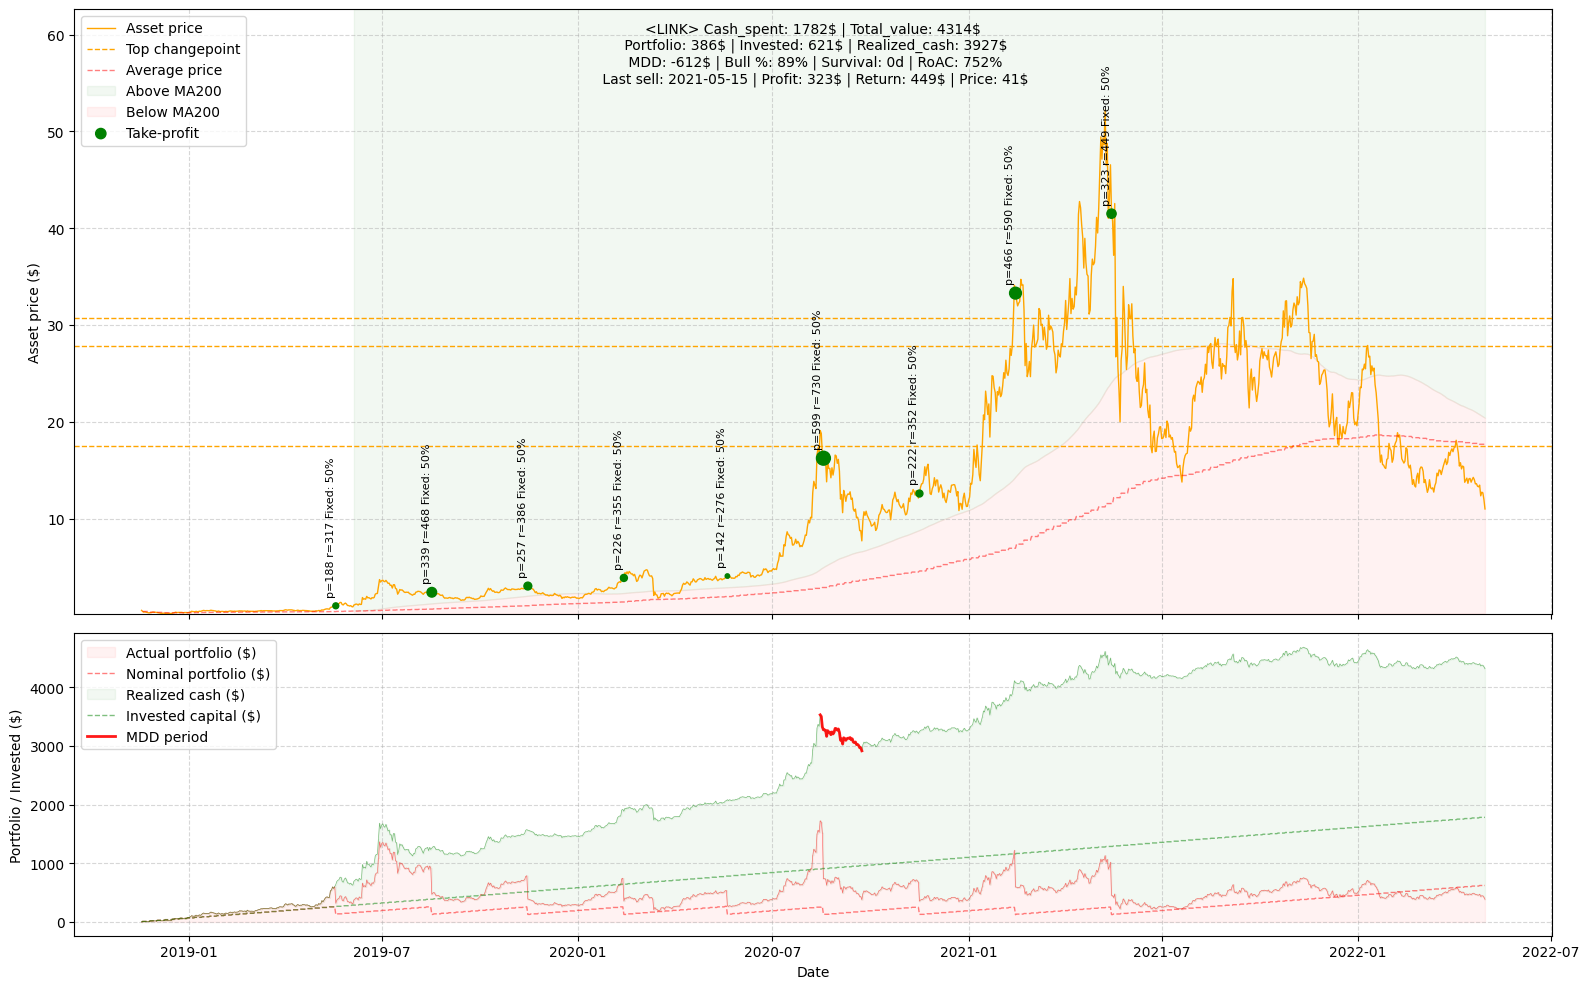

03:07:53 - cmdstanpy - INFO - Chain [1] start processing
03:07:53 - cmdstanpy - INFO - Chain [1] done processing


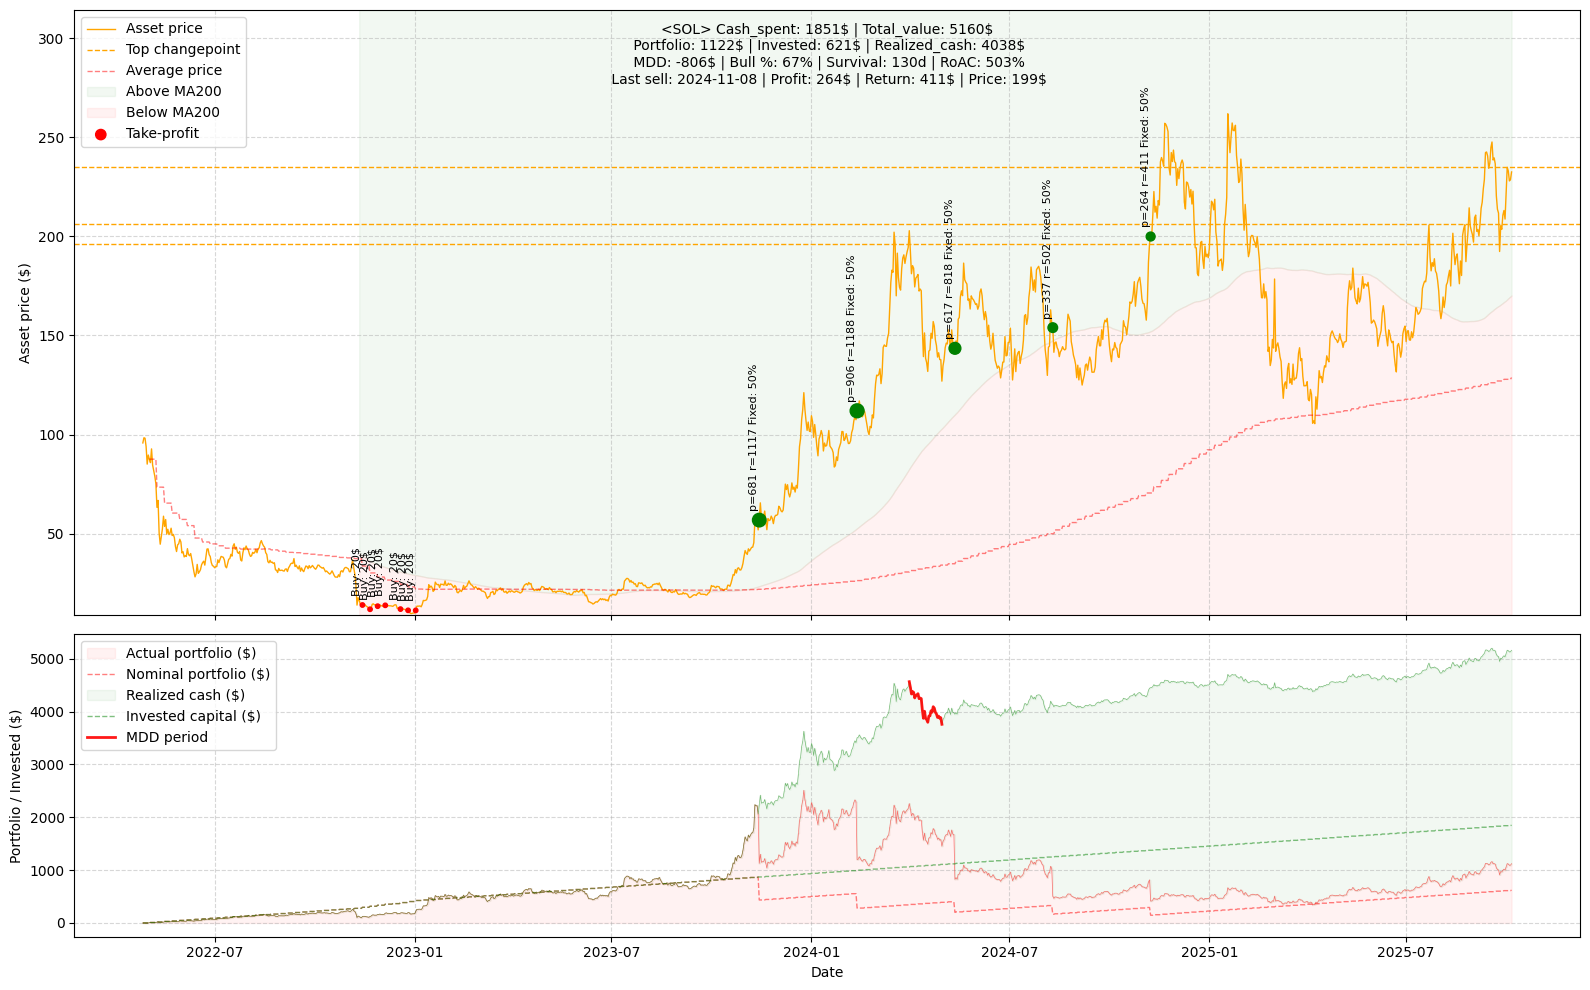

03:07:53 - cmdstanpy - INFO - Chain [1] start processing
03:07:54 - cmdstanpy - INFO - Chain [1] done processing


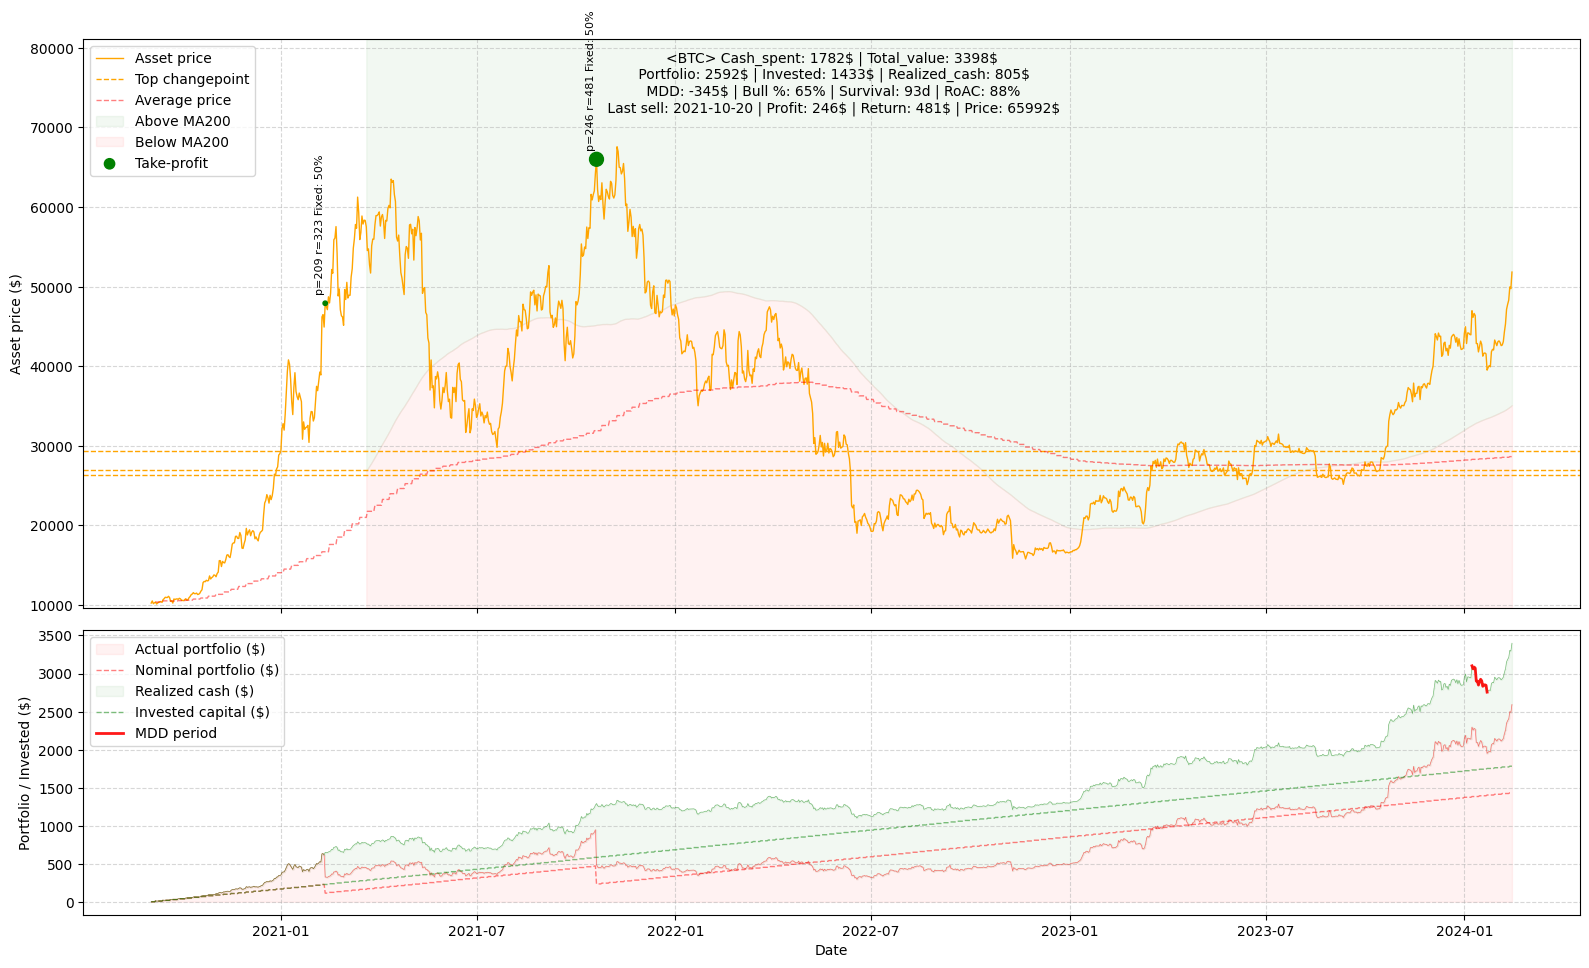

03:07:54 - cmdstanpy - INFO - Chain [1] start processing
03:07:54 - cmdstanpy - INFO - Chain [1] done processing


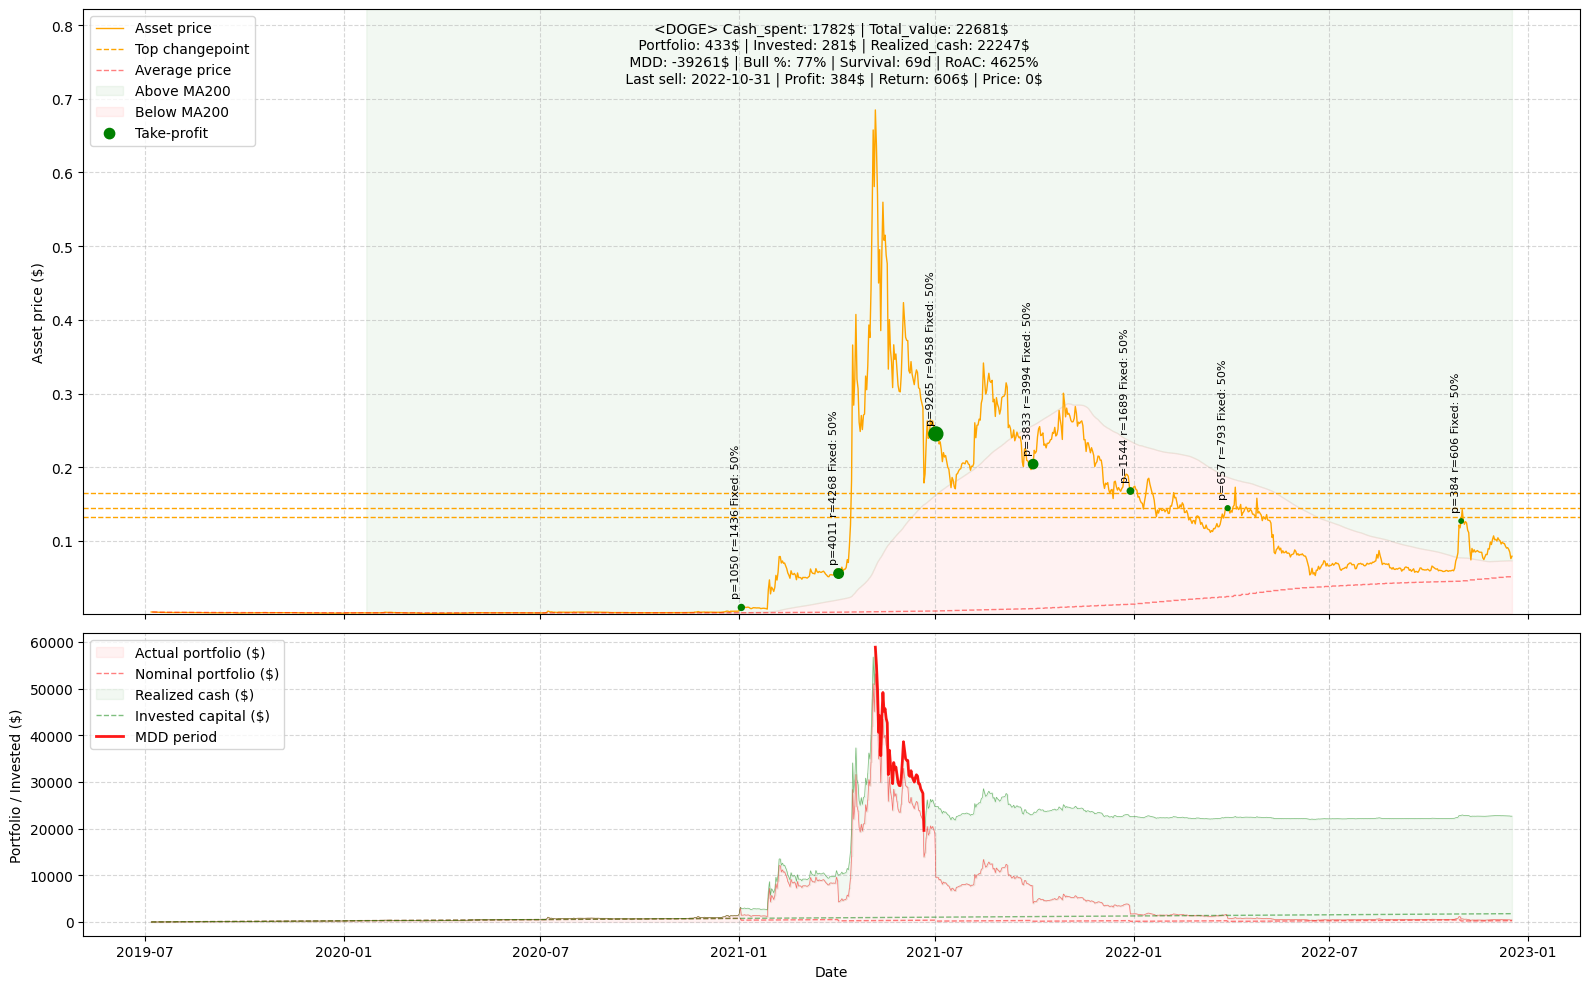

03:07:54 - cmdstanpy - INFO - Chain [1] start processing
03:07:54 - cmdstanpy - INFO - Chain [1] done processing


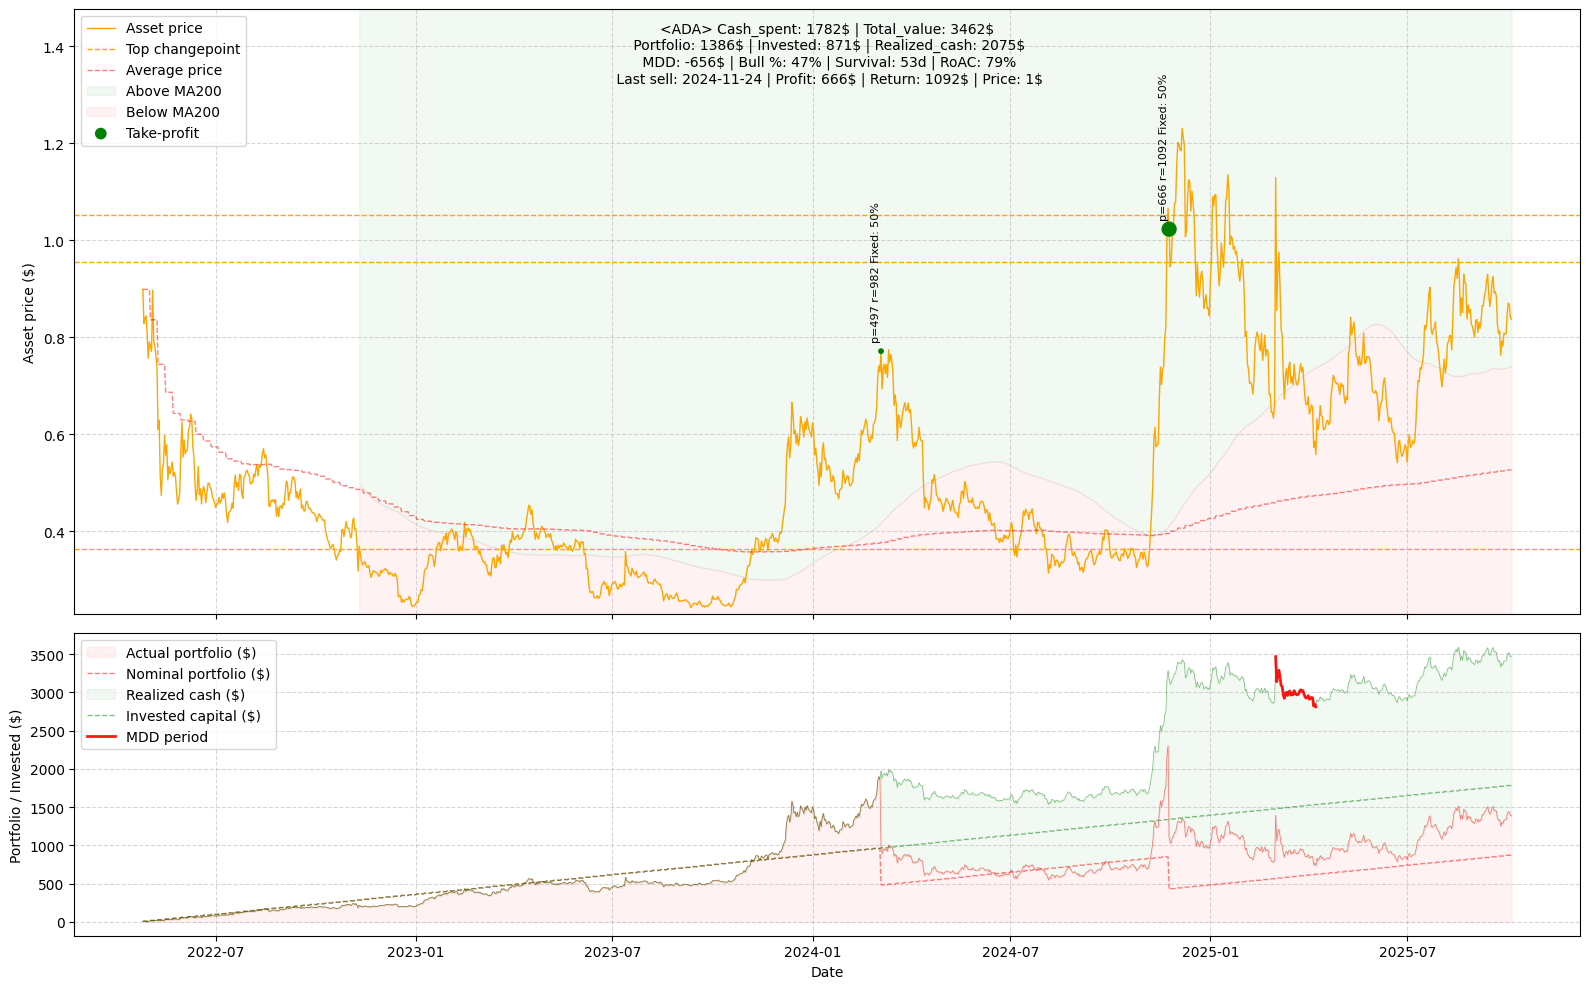

03:07:55 - cmdstanpy - INFO - Chain [1] start processing
03:07:55 - cmdstanpy - INFO - Chain [1] done processing


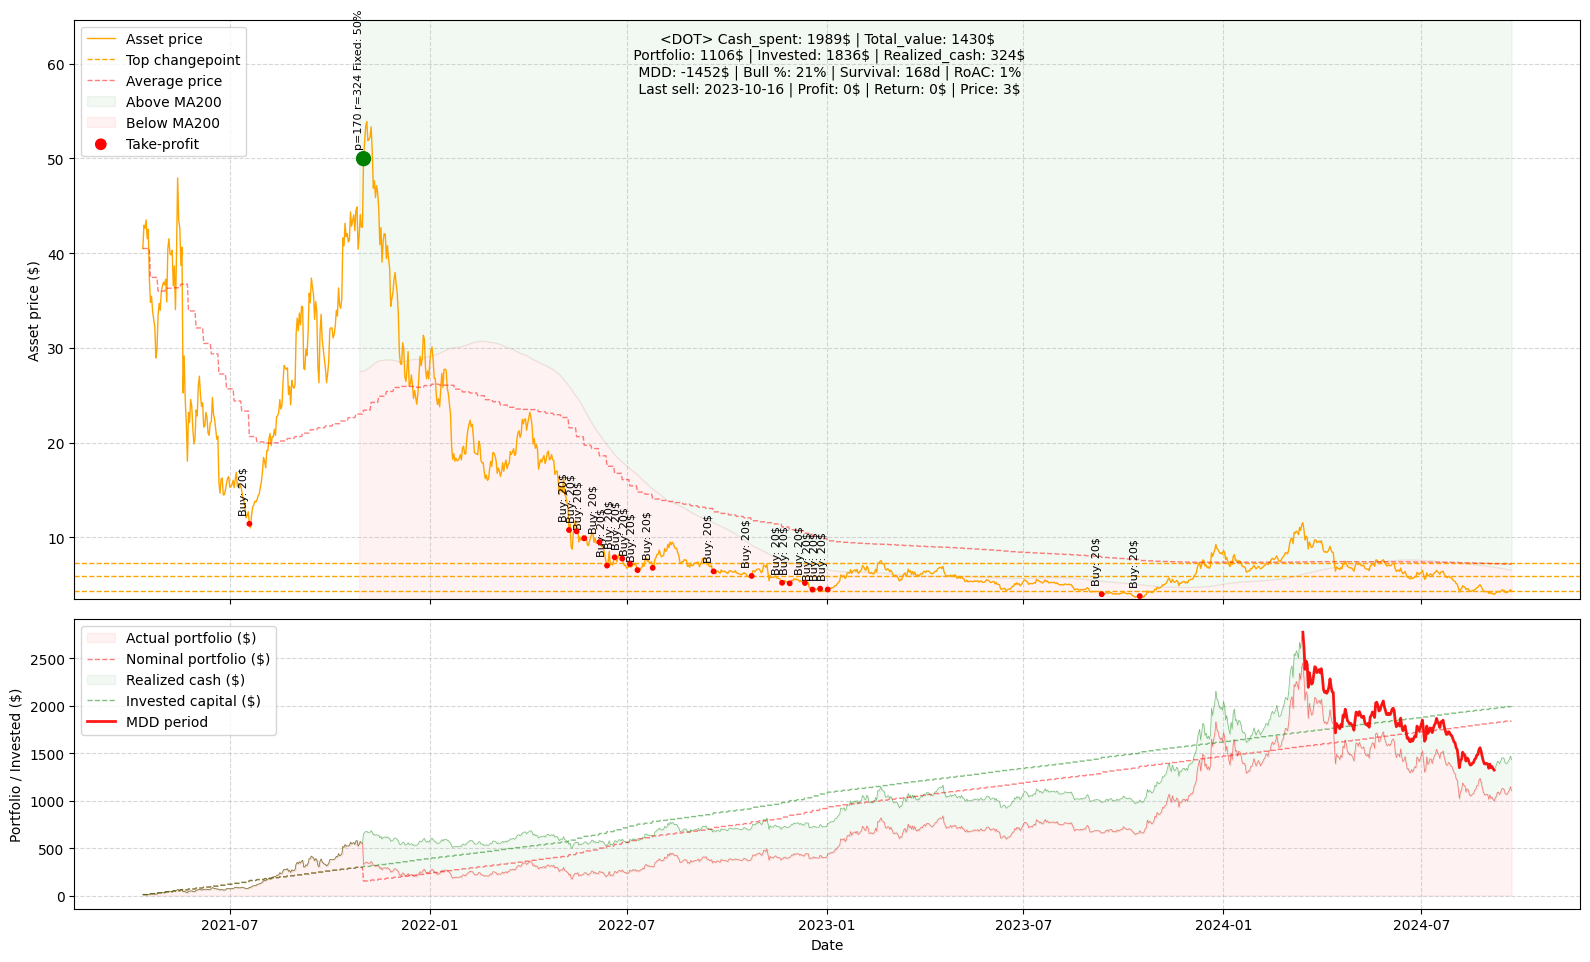

03:07:55 - cmdstanpy - INFO - Chain [1] start processing
03:07:56 - cmdstanpy - INFO - Chain [1] done processing


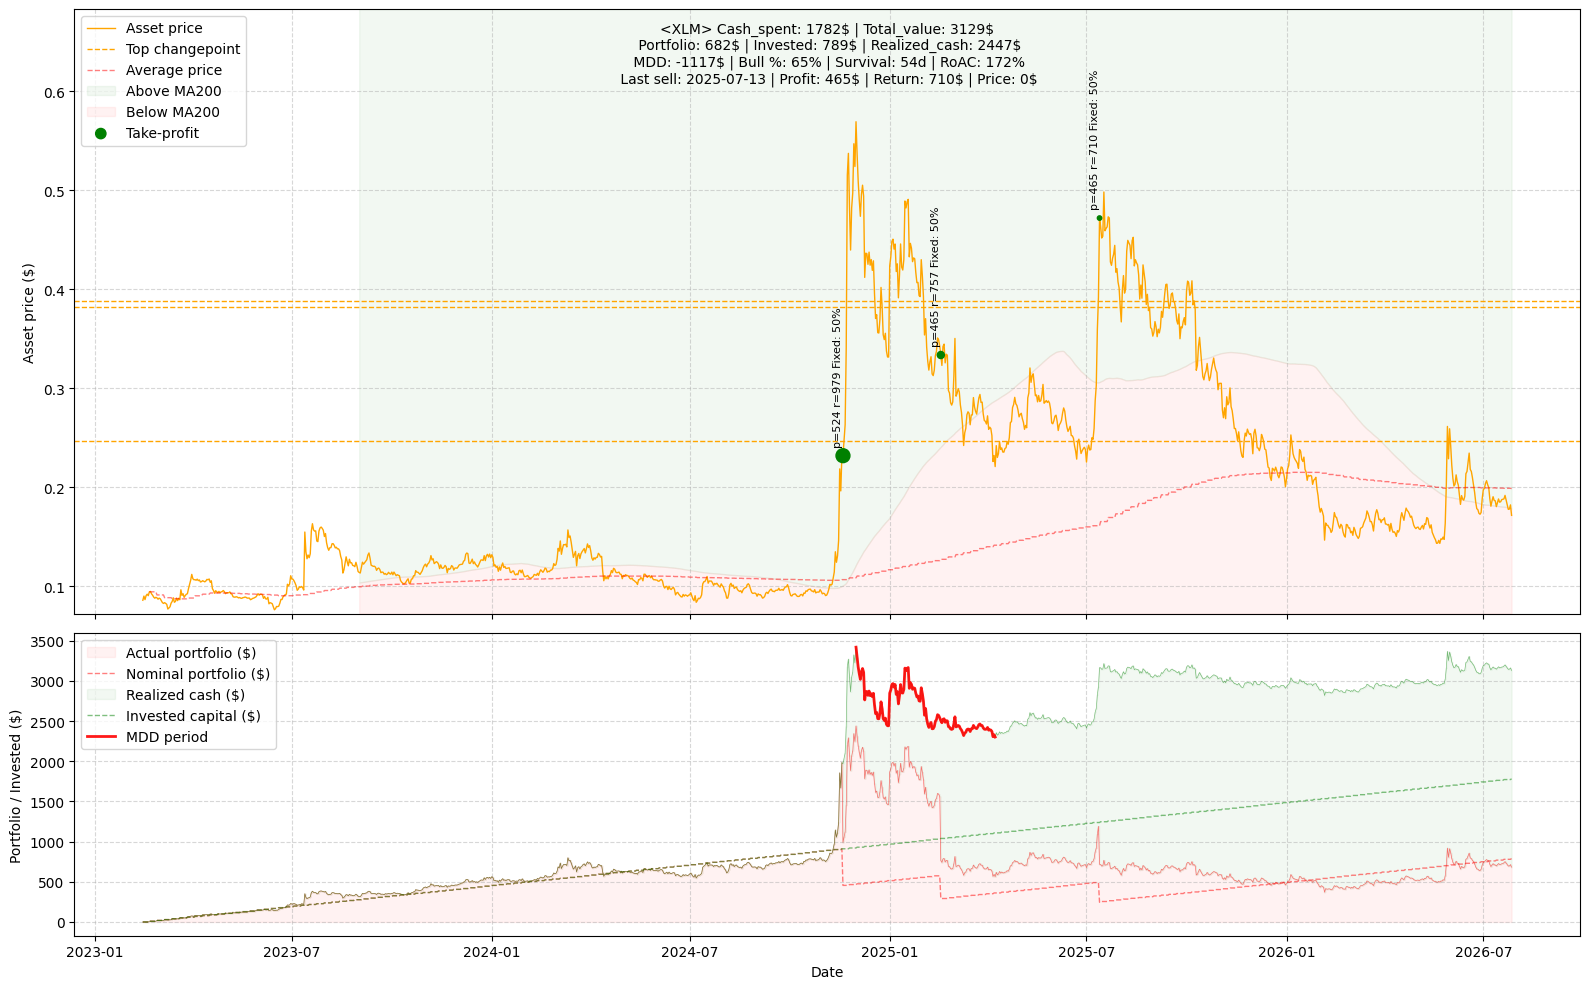

Total invested: $18154.00
Total return: $42043.00
Total value: $53871.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - sequence_length)
    prices = prices.iloc[start:start + sequence_length]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2023-02-14,0.085930,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2023-02-15,0.090156,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2023-02-16,0.086627,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2023-02-17,0.090649,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2023-02-18,0.092106,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
2026-07-23,0.182253,3915.974307,779.625,1772.1,0.0,0.0,2447.488928,,713.698078,0.199088,3161.187006
2026-07-24,0.177770,3915.974307,779.625,1772.1,0.0,0.0,2447.488928,,696.142767,0.199088,3143.631695
2026-07-25,0.178055,3915.974307,779.625,1772.1,0.0,0.0,2447.488928,,697.258818,0.199088,3144.747746


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(1254)

In [10]:
metrics

{'Target': 'XLM',
 'Cash_spent': 1782,
 'Realized_cash': 2447,
 'Portfolio': 682,
 'Invested': 789,
 'Total_value': 3129,
 'Bull_history': 65,
 'Avg_price': np.float64(0.1986913903096104),
 'Num_take_profits': 3,
 'MDD': -1117,
 'MA200_survival_days': 53.8181818181818,
 'RoAC': 172}